# Week 16 — Train and Sample a Tiny DDPM on MNIST

Use the [working copy](w16_train_tiny_ddpm_mnist_solved.ipynb) for your exercises. Both notebooks start with the same cells.

This builds on the [Week 15 forward process](../notes/w15_forward_process_discrete.md) and [Week 16 discussion](../notes/w16_hf_ddpm_training.md). Day 4 covers the training batch, one optimizer update, and a fixed-batch check. Day 5 covers reverse sampling and the full experiment.

## Setup

Reuse the Week 11 MNIST training cache when available. Select a fixed subset and normalize images to $[-1,1]$ as in Week 15. The starting configuration runs on CPU.

In [1]:
from pathlib import Path
import gzip
import hashlib
import os
import struct
import urllib.request

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir()
)
CACHE = ROOT / "scratch" / "w16_train_tiny_ddpm_mnist"
CACHE.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(CACHE / "matplotlib"))
import matplotlib.pyplot as plt

SEED = 16
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(torch.get_num_threads(), 4))
config = {
    "seed": SEED,
    "T": 1000,
    "beta_start": 1e-4,
    "beta_end": 0.02,
    "n_train": 5000,
    "batch_size": 64,
    "channels": 16,
    "learning_rate": 1e-3,
    "epochs": 30,
    "grid_count": 16,
}
assert 0 < config["beta_start"] <= config["beta_end"] < 1
print(f"CPU | seed={SEED} | T={config['T']}")

CPU | seed=16 | T=1000


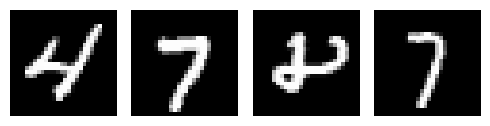

In [2]:
def load_mnist_images() -> np.ndarray:
    """Return the verified MNIST training images as uint8."""
    filename = "train-images-idx3-ubyte.gz"
    checksum = "f68b3c2dcbeaaa9fbdd348bbdeb94873"
    previous = ROOT / "scratch" / "w11_vae" / "mnist" / filename
    target = previous if previous.is_file() else CACHE / filename
    if target.is_file():
        payload = target.read_bytes()
    else:
        url = "https://ossci-datasets.s3.amazonaws.com/mnist/" + filename
        with urllib.request.urlopen(url, timeout=60) as response:
            payload = response.read()
    if hashlib.md5(payload).hexdigest() != checksum:
        raise ValueError(f"MNIST image checksum mismatch for {target}")
    if not target.is_file():
        target.write_bytes(payload)
    raw = gzip.decompress(payload)
    assert struct.unpack(">IIII", raw[:16]) == (2051, 60000, 28, 28)
    return np.frombuffer(raw, dtype=np.uint8, offset=16).reshape(-1, 28, 28)


images = load_mnist_images()
indices = rng.choice(len(images), config["n_train"], replace=False)
train_x = torch.from_numpy(images[indices, None]).float() / 127.5 - 1.0


def make_train_loader() -> DataLoader:
    """Return a loader with reproducible minibatch order."""
    return DataLoader(
        TensorDataset(train_x),
        batch_size=config["batch_size"],
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED),
    )


(clean_batch,) = next(iter(make_train_loader()))
assert clean_batch.shape == (config["batch_size"], 1, 28, 28)
assert clean_batch.min() >= -1 and clean_batch.max() <= 1

fig, axes = plt.subplots(1, 4, figsize=(5, 1.5))
for axis, image in zip(axes, clean_batch[:4]):
    axis.imshow(image[0], cmap="gray", vmin=-1, vmax=1)
    axis.axis("off")
fig.tight_layout()
plt.show()

## Step 1: Schedule and model

Schedule tables use mathematical indices $0,\ldots,T$. The entries $\beta_0=0$ and $\bar\alpha_0=1$ represent the clean boundary. Training draws timesteps from $1,\ldots,T$.

In [3]:
T = config["T"]
betas = torch.cat((torch.zeros(1), torch.linspace(config["beta_start"], config["beta_end"], T)))
alphas = 1 - betas
alpha_bar = torch.cumprod(alphas, dim=0)


def coefficient_at(table: torch.Tensor, t: torch.Tensor, batch: torch.Tensor) -> torch.Tensor:
    """Gather one coefficient per image and broadcast over its coordinates."""
    assert t.dtype == torch.long and t.shape == (batch.shape[0],)
    return table[t].reshape(batch.shape[0], 1, 1, 1)


assert alpha_bar.shape == (T + 1,) and alpha_bar[0] == 1
assert torch.all(alpha_bar[1:] < alpha_bar[:-1])
times = torch.tensor([1, T])
assert coefficient_at(alpha_bar, times, clean_batch[:2]).shape == (2, 1, 1, 1)

Follow the timestep through the model. A small network turns the scaled timestep into one value per hidden channel for each image. Broadcasting lets us add those values to the first convolution's feature map. The final convolution predicts one noise value per pixel.

In [4]:
class TinyDenoiser(nn.Module):
    """Predict image-shaped noise from a noisy image and its timestep."""

    def __init__(self, timesteps: int, channels: int):
        super().__init__()
        self.timesteps = timesteps
        self.input_conv = nn.Conv2d(1, channels, kernel_size=3, padding=1)
        self.time_projection = nn.Sequential(
            nn.Linear(1, channels),
            nn.SiLU(),
            nn.Linear(channels, channels),
        )
        self.output_layers = nn.Sequential(
            nn.SiLU(),
            nn.Conv2d(channels, channels, kernel_size=3, padding=2, dilation=2),
            nn.SiLU(),
            nn.Conv2d(channels, 1, kernel_size=3, padding=1),
        )

    def forward(self, x_t: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        t_scaled = t.to(dtype=x_t.dtype).reshape(-1, 1) / self.timesteps
        time_features = self.time_projection(t_scaled)[:, :, None, None]
        return self.output_layers(self.input_conv(x_t) + time_features)


model = TinyDenoiser(T, config["channels"])
with torch.no_grad():
    prediction = model(clean_batch[:2], times)
    assert prediction.shape == clean_batch[:2].shape and torch.isfinite(prediction).all()
print(f"Parameters: {sum(parameter.numel() for parameter in model.parameters()):,}")

Parameters: 2,929


## Exercise: Construct the training batch and update the weights

### TODO 1 — Construct one batched training example

Use the supplied generator. Decide what to draw and which shapes you need, then return the noisy images, their timesteps, and the noise target. The forward equation and the schedule lookup are available as references.

In [5]:
def prepare_batch(
    clean: torch.Tensor, generator: torch.Generator
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """Return (noisy images, timesteps, target noise) for a clean batch."""
    t = torch.randint(1, T + 1, (len(clean),), generator=generator)
    noise = torch.randn(clean.shape, dtype=clean.dtype, device=clean.device, generator=generator)
    x_t = coefficient_at(alpha_bar, t, clean).sqrt() * clean + (1 - coefficient_at(alpha_bar, t, clean)).sqrt() * noise
    return x_t, t, noise

### TODO 2 — Perform one noise-MSE optimizer update

Use the optimizer and corrupted batch passed in. Return the loss for the update as a Python float. Keep the latest gradients available for inspection after the update.

A common pitfall is forgetting that gradients accumulate across backward calls.

In [6]:
def train_step(
    model: nn.Module,
    optimizer: torch.optim.Optimizer,
    x_t: torch.Tensor,
    t: torch.Tensor,
    noise: torch.Tensor,
) -> float:
    """Perform one optimizer update and return its noise-MSE loss."""
    prediction = model(x_t, t)
    loss = nn.functional.mse_loss(prediction, noise)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return loss.item()

## Step 2: Check the result on one fixed corruption

Run this cell after filling both exercises. It uses a separate model and holds the inputs and targets fixed for 20 updates. Compare initial and final loss on that same example. Day 5 will draw a new corruption for each training batch.

Optional extension. Try a different fixed corruption and compare the losses.

Fixed batch loss: 0.9683 to 0.6795


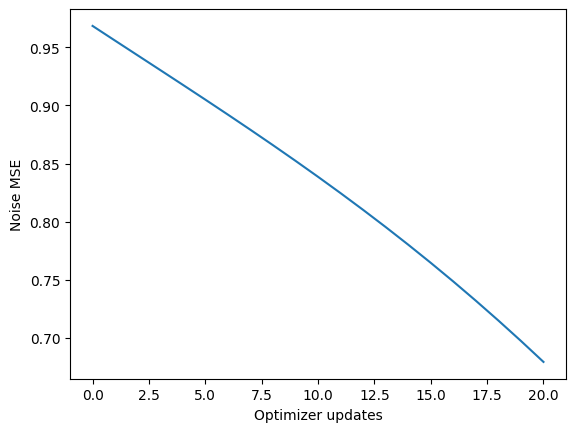

In [7]:
check_rng = torch.Generator().manual_seed(SEED + 1)
check_x0 = clean_batch[:16]
x_t, t, noise = prepare_batch(check_x0, check_rng)
assert x_t.shape == noise.shape == check_x0.shape
assert t.shape == (len(check_x0),) and t.dtype == torch.long
assert torch.all((1 <= t) & (t <= T))
assert torch.isfinite(x_t).all() and torch.isfinite(noise).all()
for i in (0, len(check_x0) - 1):
    weight = alpha_bar[t[i]]
    expected = weight.sqrt() * check_x0[i] + (1 - weight).sqrt() * noise[i]
    torch.testing.assert_close(x_t[i], expected)

torch.manual_seed(SEED)
check_model = TinyDenoiser(T, config["channels"])
optimizer = torch.optim.Adam(check_model.parameters(), lr=config["learning_rate"])
before = [parameter.detach().clone() for parameter in check_model.parameters()]
with torch.no_grad():
    initial_loss = nn.functional.mse_loss(check_model(x_t, t), noise).item()

losses = [train_step(check_model, optimizer, x_t, t, noise) for _ in range(20)]
assert np.isfinite(losses).all() and np.isfinite(initial_loss)
assert all(
    parameter.grad is not None and torch.isfinite(parameter.grad).all()
    for parameter in check_model.parameters()
)
assert any(not torch.equal(old, new) for old, new in zip(before, check_model.parameters()))
with torch.no_grad():
    final_loss = nn.functional.mse_loss(check_model(x_t, t), noise).item()
assert np.isfinite(final_loss)
print(f"Fixed batch loss: {initial_loss:.4f} to {final_loss:.4f}")
plt.plot(range(len(losses) + 1), [*losses, final_loss])
plt.xlabel("Optimizer updates")
plt.ylabel("Noise MSE")
plt.show()

## Wrap-up

Record whether the loss improved and what that shows about the training path. The first generated images will provide a separate check in Day 5. Start that session from the [reverse-loop pseudocode](../notes/w16_hf_ddpm_training.md#day-3--sampling-from-a-trained-ddpm).

## Day 5 — One reverse step

One call updates a whole batch from $x_t$ to $x_{t-1}$. The integer $t$ controls the final-step check. The model gets that same timestep repeated once per image. In the mean, the outer denominator uses $\sqrt{\alpha_t}=\sqrt{1-\beta_t}$. The noise coefficient uses $\sqrt{1-\bar\alpha_t}$ in its denominator.

For fresh noise, we use the fixed variance choice $\tilde\beta_t$ from $q(x_{t-1}\mid x_t,x_0)$.

$$
\tilde\beta_t=\beta_t\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}.
$$

The code scales a fresh draw $z$ by the **standard deviation** $\sqrt{\tilde\beta_t}$. At $t=1$, it takes the mean without drawing fresh noise. We used the variance formula as a reference. Its derivation is still open. [Day 3 pseudocode](../notes/w16_hf_ddpm_training.md#day-3--sampling-from-a-trained-ddpm)

In [8]:
def single_step_reverse(
    x_t: torch.Tensor,
    t: int,
    model: nn.Module,
    generator: torch.Generator,
) -> torch.Tensor:
    """Return one step of reverse diffusion"""
    t_tensor = torch.full((x_t.shape[0],), t, dtype=torch.long, device=x_t.device)
    predicted_noise = model(x_t, t_tensor)
    alpha_bar_t = coefficient_at(alpha_bar, t_tensor, x_t)
    alpha_bar_t_minus_1 = coefficient_at(alpha_bar, t_tensor - 1, x_t)
    beta_t = coefficient_at(betas, t_tensor, x_t)
    mean = (x_t - beta_t * predicted_noise / torch.sqrt(1 - alpha_bar_t)) / torch.sqrt(1 - beta_t)
    if t > 1:
        z = torch.randn(x_t.shape, dtype=x_t.dtype, device=x_t.device, generator=generator)
    else:
        z = torch.zeros_like(x_t)
    return mean + torch.sqrt(beta_t * (1 - alpha_bar_t_minus_1) / (1 - alpha_bar_t)) * z

## Sampling Loop

Start with $x_T\sim\mathcal N(0,I)$. The clean batch provides the image shape, dtype, and device. Every pixel in the starting state comes from the random draw. Each call's output becomes the next call's input, so the final iteration returns $x_0$. The caller controls the output count with `n_samples`.

In [9]:
@torch.no_grad()
def sample_loop(
    model: nn.Module,
    generator: torch.Generator,
    n_samples: int,
) -> torch.Tensor:
    """Return a sample from the model."""
    x_t = torch.randn((n_samples, *clean_batch.shape[1:]), dtype=clean_batch.dtype, device=clean_batch.device, generator=generator)
    for t in range(T, 0, -1):
        x_t = single_step_reverse(x_t, t, model, generator)
    return x_t

### Preview before training

Here we pass `config["grid_count"]` to generate a 4 × 4 grid. `model` is still at initialization. The fixed-batch diagnostic trained a separate `check_model`. This preview checks that the sampler gives 16 finite outputs with shape `(16, 1, 28, 28)`.

In [10]:
# Initialize the generator
noise_rng = torch.Generator().manual_seed(SEED)

n_samples = config["grid_count"]
x_0 = sample_loop(model, noise_rng, n_samples)
assert x_0.shape == (n_samples, *clean_batch.shape[1:])
assert torch.isfinite(x_0).all()

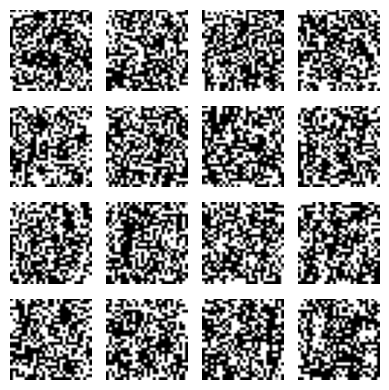

In [11]:
fig, axes = plt.subplots(4, 4, figsize=(4, 4))
for axis, image in zip(axes.flat, x_0):
    axis.imshow(image[0], cmap="gray", vmin=-1, vmax=1)
    axis.axis("off")
fig.tight_layout()
plt.show()

### Train and compare grids

After each epoch, sample with the model that just trained. Recreate the sampling generator with the same seed each time so the initial noise and fresh draws match across grids. Save the grids, the loss curve, and the training and sampling times. [Day 5 plan](../notes/w16_study_plan.md#day-5--train-then-generate-from-noise)

The saved run uses 30 epochs. See the [Day 5 experiment note](../notes/w16_hf_ddpm_training.md#day-5--training-and-generating-from-noise) for the sampler checks, runtime, and comparison of the generated grids.

In [12]:
import time

def training_loop(
    model: nn.Module,
    optimizer: torch.optim.Optimizer,
    train_loader: DataLoader,
    epochs: int,
    train_generator: torch.Generator,
    sample_seed: int
) -> dict[str, list]:
    """Return the loss curve and the training time."""
    batch_losses = []
    training_times = []
    sample_times = []
    grids = []
    epoch_losses = []
    for epoch in range(epochs):

        # Training
        start_epoch_training_time = time.perf_counter()
        # Loop in batches through dataset
        for (clean_batch,) in train_loader:
            x_t, t, noise = prepare_batch(clean_batch, train_generator)
            step_loss = train_step(model, optimizer, x_t, t, noise)
            batch_losses.append(step_loss)

        epoch_mean = sum(batch_losses[-len(train_loader):]) / len(train_loader)
        epoch_losses.append(epoch_mean)
        epoch_training_time = time.perf_counter() - start_epoch_training_time
        training_times.append(epoch_training_time)
        print(f"Epoch {epoch + 1} | loss: {epoch_mean:.4f} | train: {epoch_training_time:.2f}s")

        # Sampling
        start_sample_time = time.perf_counter()
        sample_generator = torch.Generator().manual_seed(sample_seed)
        sample = sample_loop(model, sample_generator, n_samples=config["grid_count"])
        end_sample_time = time.perf_counter()
        sample_time = end_sample_time - start_sample_time
        sample_times.append(sample_time)
        print(f"Sample time for epoch {epoch + 1}: {sample_time:.2f}s")
        grids.append(sample)

        # Plotting
        fig, axes = plt.subplots(4, 4, figsize=(4, 4))
        for axis, image in zip(axes.flat, sample):
            axis.imshow(image[0], cmap="gray", vmin=-1, vmax=1)
            axis.axis("off")
        fig.suptitle(f"Epoch {epoch + 1}")
        fig.tight_layout()
        plt.show()

    return {
        "batch_losses": batch_losses,   # per-batch loss
        "epoch_losses": epoch_losses,   # mean loss per epoch
        "grids": grids,                 # one (grid_count, 1, 28, 28) tensor per epoch
        "train_times": training_times,  # seconds spent training each epoch
        "sample_times": sample_times,   # seconds spent sampling each epoch
    }

Epoch 1 | loss: 0.4860 | train: 2.35s
Sample time for epoch 1: 1.74s


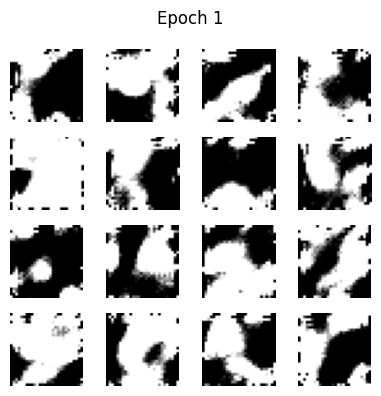

Epoch 2 | loss: 0.2044 | train: 2.23s
Sample time for epoch 2: 1.72s


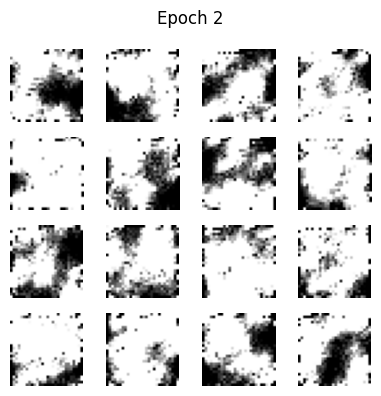

Epoch 3 | loss: 0.1720 | train: 2.54s
Sample time for epoch 3: 1.96s


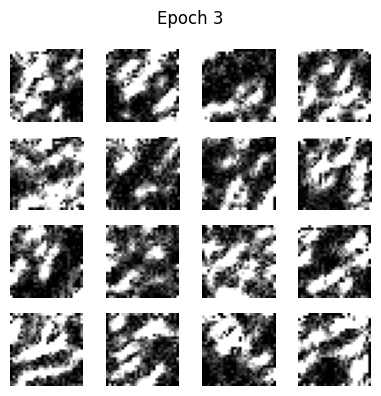

Epoch 4 | loss: 0.1405 | train: 2.05s
Sample time for epoch 4: 1.66s


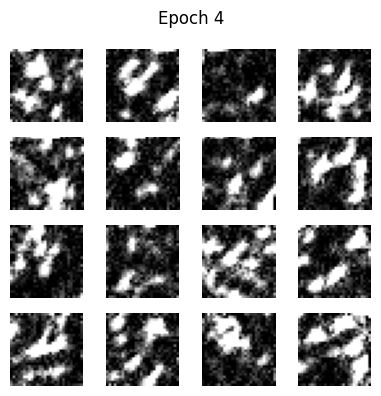

Epoch 5 | loss: 0.1225 | train: 2.09s
Sample time for epoch 5: 1.63s


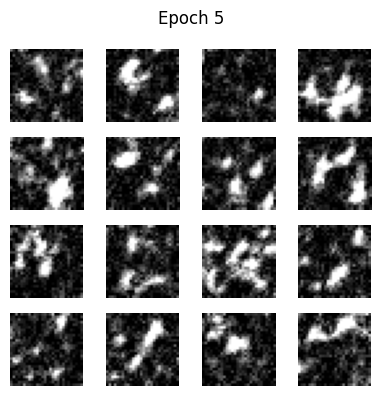

Epoch 6 | loss: 0.1105 | train: 1.98s
Sample time for epoch 6: 1.64s


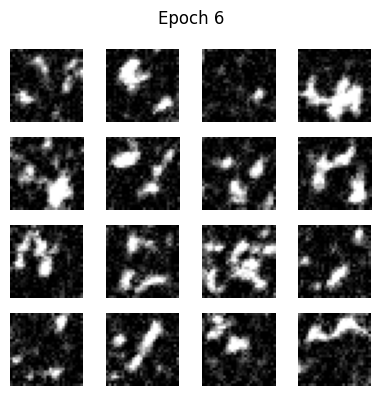

Epoch 7 | loss: 0.1018 | train: 1.96s
Sample time for epoch 7: 1.64s


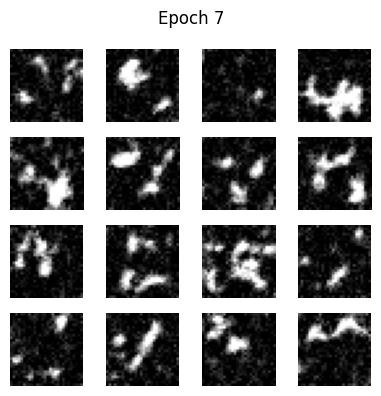

Epoch 8 | loss: 0.0986 | train: 2.04s
Sample time for epoch 8: 1.64s


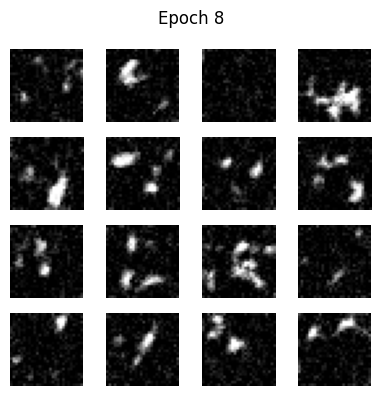

Epoch 9 | loss: 0.0933 | train: 1.97s
Sample time for epoch 9: 1.65s


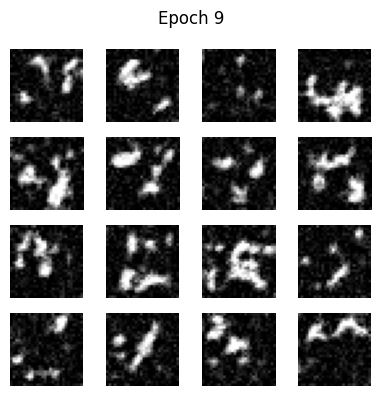

Epoch 10 | loss: 0.0889 | train: 1.97s
Sample time for epoch 10: 1.61s


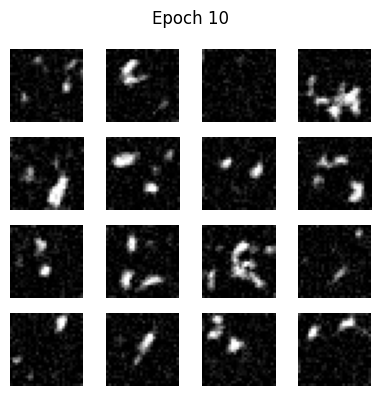

Epoch 11 | loss: 0.0800 | train: 1.97s
Sample time for epoch 11: 1.86s


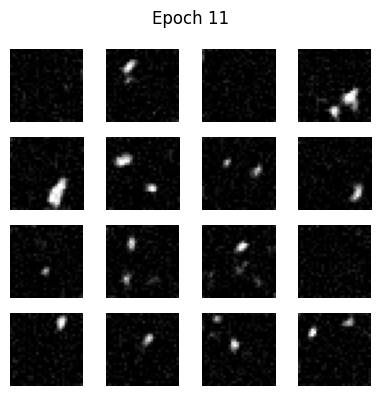

Epoch 12 | loss: 0.0780 | train: 2.02s
Sample time for epoch 12: 1.62s


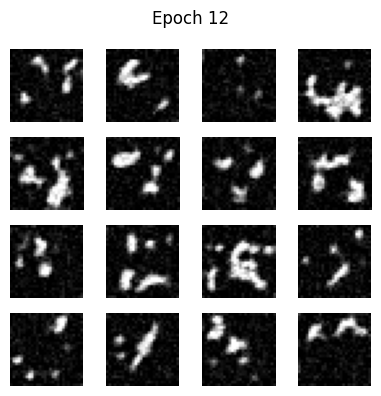

Epoch 13 | loss: 0.0733 | train: 1.95s
Sample time for epoch 13: 1.62s


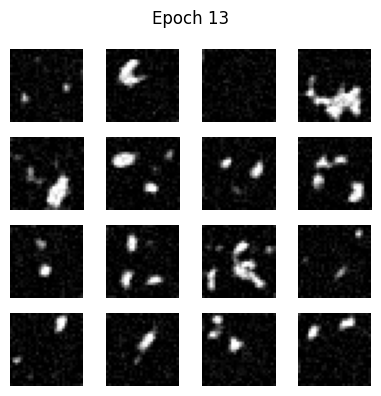

Epoch 14 | loss: 0.0718 | train: 1.95s
Sample time for epoch 14: 1.63s


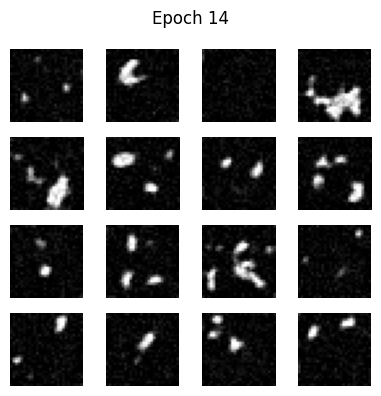

Epoch 15 | loss: 0.0705 | train: 1.97s
Sample time for epoch 15: 1.64s


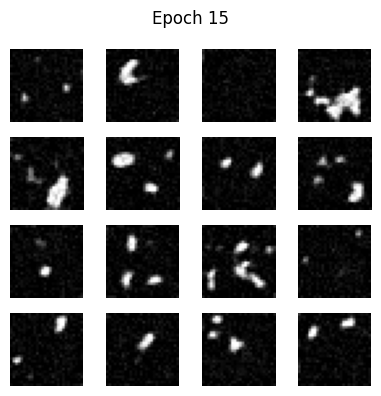

Epoch 16 | loss: 0.0684 | train: 1.98s
Sample time for epoch 16: 1.67s


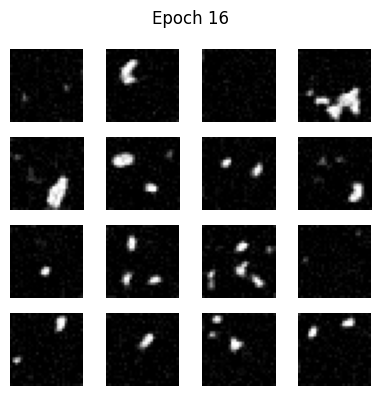

Epoch 17 | loss: 0.0688 | train: 2.03s
Sample time for epoch 17: 1.70s


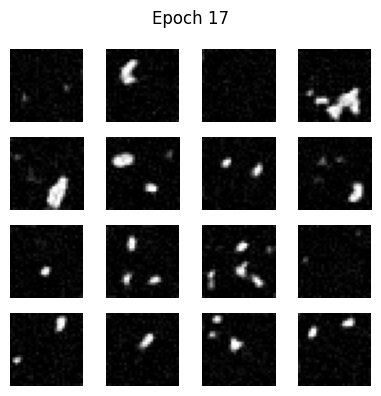

Epoch 18 | loss: 0.0666 | train: 1.98s
Sample time for epoch 18: 1.66s


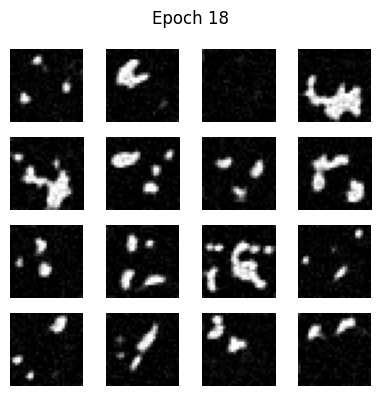

Epoch 19 | loss: 0.0612 | train: 2.32s
Sample time for epoch 19: 2.04s


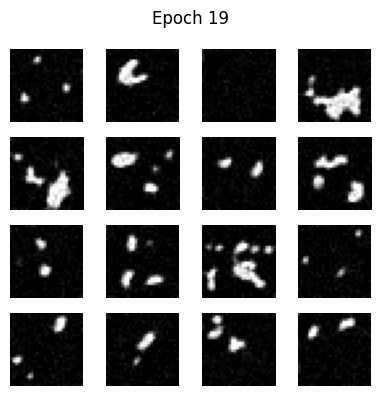

Epoch 20 | loss: 0.0610 | train: 2.10s
Sample time for epoch 20: 1.93s


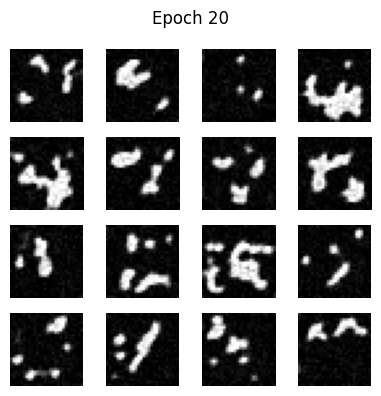

Epoch 21 | loss: 0.0590 | train: 2.21s
Sample time for epoch 21: 1.98s


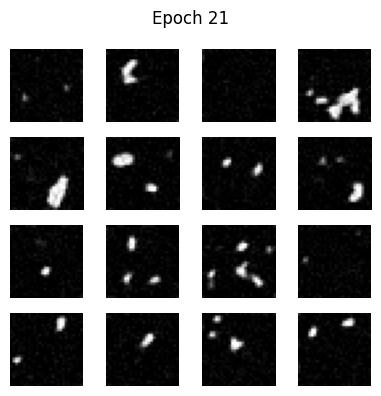

Epoch 22 | loss: 0.0599 | train: 2.18s
Sample time for epoch 22: 1.70s


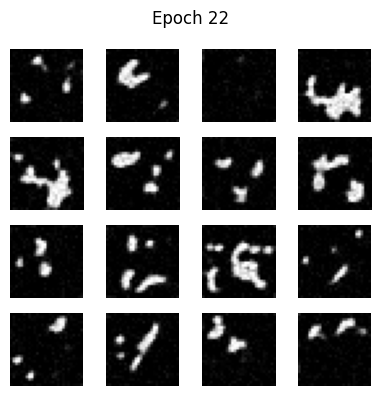

Epoch 23 | loss: 0.0595 | train: 2.04s
Sample time for epoch 23: 1.75s


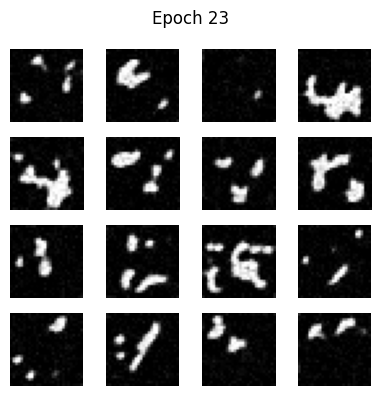

Epoch 24 | loss: 0.0545 | train: 2.03s
Sample time for epoch 24: 1.69s


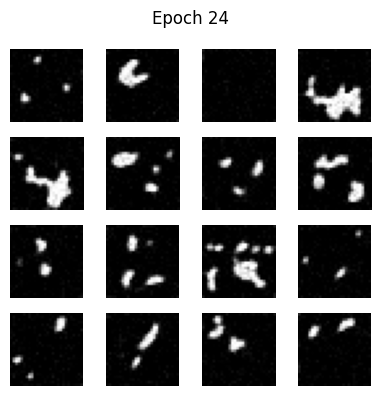

Epoch 25 | loss: 0.0580 | train: 2.04s
Sample time for epoch 25: 1.73s


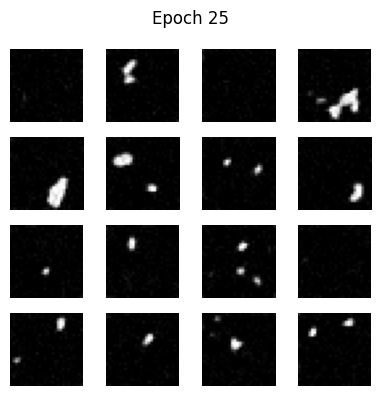

Epoch 26 | loss: 0.0564 | train: 2.00s
Sample time for epoch 26: 1.77s


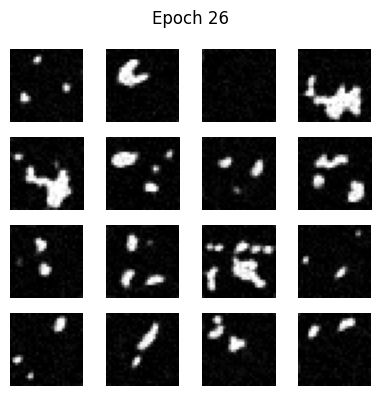

Epoch 27 | loss: 0.0580 | train: 2.03s
Sample time for epoch 27: 1.75s


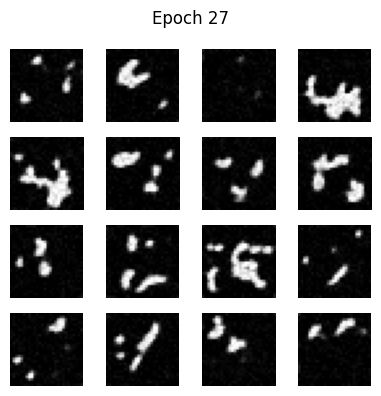

Epoch 28 | loss: 0.0571 | train: 2.03s
Sample time for epoch 28: 1.84s


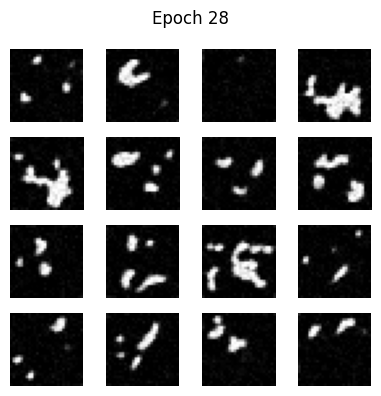

Epoch 29 | loss: 0.0548 | train: 2.02s
Sample time for epoch 29: 1.70s


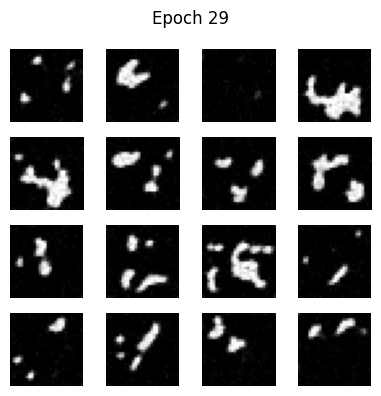

Epoch 30 | loss: 0.0543 | train: 2.16s
Sample time for epoch 30: 1.70s


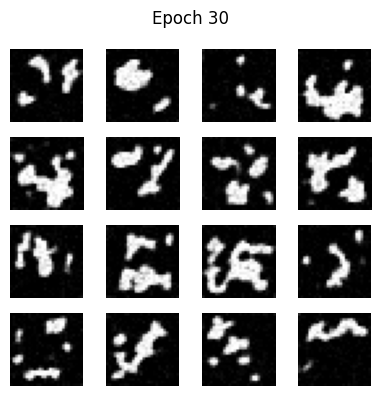

In [13]:
torch.manual_seed(SEED)
model = TinyDenoiser(T, config["channels"])
optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
train_loader = make_train_loader()
train_rng = torch.Generator().manual_seed(SEED)

results = training_loop(
    model=model,
    optimizer=optimizer,
    train_loader=train_loader,
    epochs=config["epochs"],
    train_generator=train_rng,
    sample_seed=config["seed"],
)

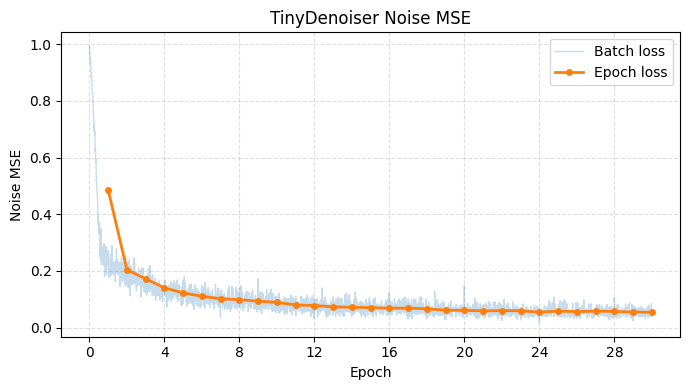

In [14]:
n_epochs = len(results["epoch_losses"])
batch_x = np.linspace(0, n_epochs, len(results["batch_losses"]))
epoch_x = np.arange(1, n_epochs  + 1)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(batch_x, results["batch_losses"], alpha=0.25, linewidth=1, label="Batch loss")
ax.plot(epoch_x, results["epoch_losses"], marker="o", linewidth=2, markersize=4, label="Epoch loss")
ax.set_title("TinyDenoiser Noise MSE")
ax.set_xlabel("Epoch")
ax.set_ylabel("Noise MSE")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()
fig.tight_layout()
plt.show()